## **Bussiness Problem**

- The data shown here simulates a medical study in which  mice infected with a virus were given various doses of two medicines and then checked 2 weeks later to see if they were still infected.

**Goal is to create a classification model that predict (given two dosage measurements) if they mouse will still be infected with the virus.**

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
data = pd.read_csv('mouse_viral_study.csv')
data.head()

,Med_1_mL,Med_2_mL,Virus Present
0,6.508231,8.582531,0
1,4.126116,3.073459,1
2,6.427870,6.369758,0
3,3.672953,4.905215,1
4,1.580321,2.440562,1


In [20]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Med_1_mL       400 non-null    float64
 1   Med_2_mL       400 non-null    float64
 2   Virus Present  400 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 9.5 KB


In [21]:
data['Virus Present'].value_counts()

Virus Present
0    200
1    200
Name: count, dtype: int64

In [22]:
data.isnull().sum()

Med_1_mL         0
Med_2_mL         0
Virus Present    0
dtype: int64

### **EDA**

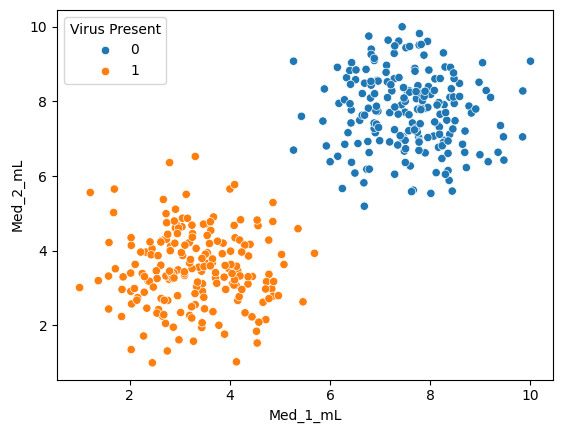

In [23]:
sns.scatterplot(x = 'Med_1_mL', y = 'Med_2_mL', hue = 'Virus Present', data = data)
plt.show()

In [24]:
X = data.drop('Virus Present', axis=1)
y = data['Virus Present']

In [25]:
# from sklearn.model_selection import train_test_split

# Train = []
# Test = []
# CV =[]

# for i in range(1,101):
#     from sklearn.model_selection import train_test_split
#     X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=i)

#     from sklearn.svm import SVC
#     log_default  = SVC()
#     log_default.fit(X_train, y_train)
#     # log_default.f(X_train, y_train)

#     y_pred_train = log_default.predict(X_train)
#     y_Pred_test = log_default.predict(X_test)

#     from sklearn.metrics import accuracy_score
#     Train.append(accuracy_score(y_train, y_pred_train))
#     Test.append(accuracy_score(y_test,y_Pred_test))

#     from sklearn.model_selection import cross_val_score
#     CV.append(cross_val_score(log_default, X_train, y_train, cv = 5, scoring='accuracy').mean())

# em = pd.DataFrame({'Train':Train,'Test':Test,'CV':CV})

# gm = em[(abs(em['Train']-em['Test'])<=0.05)& (abs(em['Test']-em['CV'])<=0.05)]

# rs = gm[gm['CV']==gm['CV'].max()].index.to_list()[0]
# print('Best random_state number : ',rs)


In [26]:
from sklearn.model_selection import train_test_split

X_train , X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,random_state=0)

In [27]:
# Modelling

from sklearn.svm import SVC

model = SVC()

model.fit(X_train, y_train)

# Prediction

y_Pred_test = model.predict(X_test)
y_pred_train = model.predict(X_train)


# accuracy

from sklearn.metrics import accuracy_score

print(accuracy_score(y_train, y_pred_train))
print(accuracy_score(y_test, y_Pred_test))

1.0
1.0


### **Hyperparameter Tuning**

In [28]:
from sklearn.model_selection import GridSearchCV

estimator = SVC()

param_grid = {'C':[0.01, 0.1, 1, 10, 100], 'kernel':['linear', 'rbf','sigmoid','poly']}

grid = GridSearchCV(estimator, param_grid, cv= 5)

grid.fit(X, y)

,estimator,SVC()
,param_grid,"{'C': [0.01, 0.1, ...], 'kernel': ['linear', 'rbf', ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,0.01


In [29]:
grid.best_params_

{'C': 0.01, 'kernel': 'linear'}

### **Rebuid the SVM model with best parameters**

In [30]:
model = SVC(kernel='linear', C=0.01)
model.fit(X_train, y_train)
y_Pred_test = model.predict(X_test)
y_pred_train = model.predict(X_train)

print(accuracy_score(y_pred_train, y_train))
print(accuracy_score(y_Pred_test, y_test))

1.0
1.0
